# AI-Assisted Equity Pairs Research

A sample-work walkthrough by Carter Sheley. This notebook reads the included reference results; it does not download prices or rerun model selection. Saved outputs can be viewed immediately. The source code and tests are separate, readable files.

**Result:** zero strict pairs, ten exploratory pairs, and unavailable aggregate exploratory return because of incomplete valuations.

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/model/run_model_v2.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from within the extracted repository.")
RESULTS = ROOT / "results/reference"
print("Reading packaged reference outputs")

Reading packaged reference outputs


## Data and chronology
The frozen end-2023 universe contains 904 securities. Development and refit each retained 821 equities in the recorded run. Earlier selection bias remains; 2024–2025 is a conditional evaluation.

In [4]:
manifest = json.loads((RESULTS / "model_v2_manifest.json").read_text())
display(pd.DataFrame([manifest["config"]["periods"]]))
u = pd.read_csv(ROOT / "data/universe/equity_universe_2023.csv")
print("Universe securities:", len(u))
display(u.head())

Universe securities: 904


,development_start,development_end,validation_start,validation_end,test_start,test_end
0,2021-01-01,2022-12-30,2023-01-01,2023-12-29,2024-01-01,2025-12-31


,universe_security_id,as_of_date,historical_ticker,company_name,index_membership,share_class_explicit,sector,sector_status,sec_cik,cik_status,candidate_cik,candidate_company_name,candidate_cik_source,cusip,isin,sedol,permanent_security_id,permanent_id_status,membership_status,membership_source,membership_corroboration,sector_source,cik_source,security_identifier_source,boundary_source,reviewed_event_types,event_review_status,price_data_status,retain_in_historical_universe,quality_flags,retrieved_date
0,U20231229_SP500_A,2023-12-29,A,Agilent Technologies,S&P 500,NaN,Health Care,dated_2023_12_29_archive,1090872.0,dated_Wikipedia_not_individually_SEC_verified,NaN,NaN,NaN,00846U101,US00846U1016,2520153,NaN,not_available_from_verified_public_sources,dated_archive_plus_dated_fund_proxy,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,NaN,NaN,no_primary_event_review_not_evidence_of_no_events,not_requested_not_tested,yes,NaN,2026-10-20
1,U20231229_SP500_AAL,2023-12-29,AAL,American Airlines Group,S&P 500,NaN,Industrials,dated_2023_12_29_archive,6201.0,dated_Wikipedia_not_individually_SEC_verified,NaN,NaN,NaN,02376R102,US02376R1023,BCV7KT2,NaN,not_available_from_verified_public_sources,dated_archive_plus_dated_fund_proxy,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,NaN,NaN,no_primary_event_review_not_evidence_of_no_events,not_requested_not_tested,yes,NaN,2026-10-20
2,U20231229_SP500_AAPL,2023-12-29,AAPL,Apple Inc.,S&P 500,NaN,Information Technology,dated_2023_12_29_archive,320193.0,dated_Wikipedia_not_individually_SEC_verified,NaN,NaN,NaN,037833100,US0378331005,2046251,NaN,not_available_from_verified_public_sources,dated_archive_plus_dated_fund_proxy,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,NaN,NaN,no_primary_event_review_not_evidence_of_no_events,not_requested_not_tested,yes,NaN,2026-10-20
3,U20231229_SP500_ABBV,2023-12-29,ABBV,AbbVie,S&P 500,NaN,Health Care,dated_2023_12_29_archive,1551152.0,dated_Wikipedia_not_individually_SEC_verified,NaN,NaN,NaN,00287Y109,US00287Y1091,B92SR70,NaN,not_available_from_verified_public_sources,dated_archive_plus_dated_fund_proxy,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,NaN,NaN,no_primary_event_review_not_evidence_of_no_events,not_requested_not_tested,yes,NaN,2026-10-20
4,U20231229_SP500_ABNB,2023-12-29,ABNB,Airbnb,S&P 500,NaN,Consumer Discretionary,dated_2023_12_29_archive,1559720.0,dated_Wikipedia_not_individually_SEC_verified,NaN,NaN,NaN,009066101,US0090661010,BMGYYH4,NaN,not_available_from_verified_public_sources,dated_archive_plus_dated_fund_proxy,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,https://raw.githubusercontent.com/riazarbi/sp5...,NaN,NaN,no_primary_event_review_not_evidence_of_no_events,not_requested_not_tested,yes,NaN,2026-10-20


## PCA exposures and Ward clustering
Stocks are standardized over training data. PCA identifies common factors; eigenvector coefficients scaled by square roots of eigenvalues describe stock exposures. Ward clustering groups those exposures. The table below is the corrected 2021–2023 V1 discovery snapshot; V2 uses a separate earlier development stage and then refits through 2023.

In [6]:
display(pd.read_csv(ROOT / "results/v1/pca_explained_variance.csv").head(20))
display(pd.read_csv(ROOT / "results/v1/ward_cluster_assignments.csv").head(10))

,component,explained_variance_ratio,cumulative_variance_ratio,eigenvalue
0,PC001,0.348746,0.348746,286.320219
1,PC002,0.049704,0.398449,40.806700
2,PC003,0.047255,0.445704,38.796323
3,PC004,0.019231,0.464936,15.788904
4,PC005,0.017496,0.482432,14.364626
5,PC006,0.013704,0.496136,11.250917
6,PC007,0.011780,0.507916,9.671604
7,PC008,0.010500,0.518416,8.620383
8,PC009,0.009617,0.528033,7.895674
9,PC010,0.008974,0.537007,7.367432


,universe_security_id,historical_ticker,company_name,ward_cluster,cluster_size,pca_components,cumulative_variance_explained
0,U20231229_SP500_A,A,Agilent Technologies,20,21,16,0.57463
1,U20231229_SP500_AAL,AAL,American Airlines Group,27,44,16,0.57463
2,U20231229_SP500_AAPL,AAPL,Apple Inc.,16,16,16,0.57463
3,U20231229_SP500_ABBV,ABBV,AbbVie,5,19,16,0.57463
4,U20231229_SP500_ABNB,ABNB,Airbnb,27,44,16,0.57463
5,U20231229_SP500_ABT,ABT,Abbott,20,21,16,0.57463
6,U20231229_SP500_ACGL,ACGL,Arch Capital Group,24,23,16,0.57463
7,U20231229_SP500_ACN,ACN,Accenture,22,23,16,0.57463
8,U20231229_SP500_ADBE,ADBE,Adobe Inc.,16,16,16,0.57463
9,U20231229_SP500_ADI,ADI,Analog Devices,15,26,16,0.57463


## Strict versus exploratory selection
The strict strategy adds the FDR filter. Exploratory selection uses validation economics and does not establish statistical qualification. Unavailable valuations remain missing.

In [8]:
curve = pd.read_csv(RESULTS / "portfolio_equity_curve.csv")
rows = []
for mode, g in curve.groupby("strategy", sort=False):
    count = manifest["selected_counts"][mode]
    terminal = g.equity_fixed_capital.iloc[-1]
    rows.append({"strategy":mode, "selected_pairs":count, "test_net_return":terminal-1,
                 "status":"cash / no pairs" if count == 0 else ("valuation incomplete" if pd.isna(terminal) else "complete")})
display(pd.DataFrame(rows))
selected = pd.read_csv(RESULTS / "selected_pairs.csv")
cols = [x for x in ["strategy", "pair_id", "y", "x", "q_value", "overall_score"] if x in selected]
display(selected[cols])

,strategy,selected_pairs,test_net_return,status
0,strict,0,0.0,cash / no pairs
1,exploratory,10,NaN,valuation incomplete


,strategy,pair_id,y,x,q_value,overall_score
0,exploratory,U20231229_SP400_ARWR__U20231229_SP400_PGNY,U20231229_SP400_PGNY,U20231229_SP400_ARWR,0.543368,0.866568
1,exploratory,U20231229_SP400_BRX__U20231229_SP400_KRG,U20231229_SP400_BRX,U20231229_SP400_KRG,1.000000,0.853300
2,exploratory,U20231229_SP500_CCL__U20231229_SP500_NCLH,U20231229_SP500_NCLH,U20231229_SP500_CCL,0.903919,0.841722
3,exploratory,U20231229_SP400_PK__U20231229_SP500_HST,U20231229_SP500_HST,U20231229_SP400_PK,0.543368,0.833915
4,exploratory,U20231229_SP500_MO__U20231229_SP500_T,U20231229_SP500_MO,U20231229_SP500_T,0.553773,0.831150
5,exploratory,U20231229_SP400_GPK__U20231229_SP400_SON,U20231229_SP400_SON,U20231229_SP400_GPK,0.517533,0.822100
6,exploratory,U20231229_SP400_JLL__U20231229_SP500_CBRE,U20231229_SP500_CBRE,U20231229_SP400_JLL,0.732012,0.814389
7,exploratory,U20231229_SP400_NVT__U20231229_SP500_WAB,U20231229_SP500_WAB,U20231229_SP400_NVT,0.459603,0.813743
8,exploratory,U20231229_SP400_RLI__U20231229_SP400_SIGI,U20231229_SP400_SIGI,U20231229_SP400_RLI,0.553773,0.806109
9,exploratory,U20231229_SP400_PCTY__U20231229_SP500_PAYC,U20231229_SP400_PCTY,U20231229_SP500_PAYC,0.875066,0.804536


## Ranking and diagnostics
These scores use development/validation information. They are not independent evidence of out-of-sample profit.

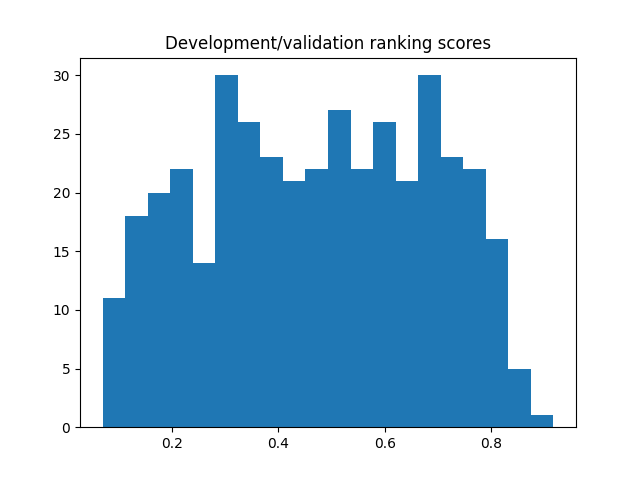

,pair_id,overall_score,q_value,net_return,label
0,U20231229_SP400_CRI__U20231229_SP500_BBY,0.916655,0.617745,0.118165,exploratory
1,U20231229_SP400_ARWR__U20231229_SP400_PGNY,0.866568,0.880155,0.214041,exploratory
2,U20231229_SP400_BRX__U20231229_SP400_KRG,0.853300,0.735639,0.048577,exploratory
3,U20231229_SP500_CCL__U20231229_SP500_NCLH,0.841722,1.000000,0.150668,exploratory
4,U20231229_SP400_HXL__U20231229_SP500_HWM,0.838281,0.617745,0.101875,exploratory
5,U20231229_SP400_PK__U20231229_SP500_HST,0.833915,0.717738,0.658728,exploratory
6,U20231229_SP500_MO__U20231229_SP500_T,0.831150,0.830091,0.187232,exploratory
7,U20231229_SP500_CFG__U20231229_SP500_KEY,0.823916,1.000000,0.120479,exploratory
8,U20231229_SP400_GPK__U20231229_SP400_SON,0.822100,0.808324,0.178186,exploratory
9,U20231229_SP400_SFM__U20231229_SP500_IRM,0.820852,0.830091,0.159472,exploratory


In [10]:
display(Image(filename=str(RESULTS / "charts/ranking_scores.png"), width=850))
ranked = pd.read_csv(RESULTS / "ranked_pairs.csv")
cols = [x for x in ["pair_id", "overall_score", "q_value", "net_return", "label"] if x in ranked]
display(ranked[cols].head(10))

## Reproduction and interpretation
Run `python run.py test` to check the accounting tests. To rerun discovery/backtesting, supply the local adjusted-price matrix described in `data/README.md`, then run `python run.py model`. Each run writes a new directory.

See `AI_COLLABORATION.md` for the AI role and `docs/KNOWN_LIMITATIONS.md` for remaining gaps. The project demonstrates an inspectable research workflow; it does not claim a proven strategy.